# SPoD × Video：業配貼文偵測模型
流程：Posts → Encoders → Aspect Attention → Hidden Layer → Sponsorship Scores → Ranked Result
目前進度：只用 Text Encoder 跑通整條流程（pilot，299 篇）

# 0. 匯入 Package 與共通參數

In [3]:
import re, unicodedata, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, BertTokenizerFast
from sklearn.metrics import average_precision_score

In [4]:
# ── 資料模式 ──
DATA_MODE = "pilot"        # "pilot"：299 篇跑通流程；"full"：正式 7:1:2 實驗

ROOT      = Path("/home/yingtzudai/Multimodal_SPoD_Video")
PILOT_CSV = ROOT / "data/split/pilot_posts.csv"
FULL_CSV  = ROOT / "data/split/all_posts.csv"         # ← 正式資料的路徑，之後再填
POSTS_CSV = PILOT_CSV if DATA_MODE == "pilot" else FULL_CSV

DATA_ROOT = Path("/home/ftp_246/data_5/多模態2026_ig_top200")
META_DIR  = DATA_ROOT / "Metadata_by_Influencer"      # {username}-FullVideoInfo.csv
VIDEO_DIR = DATA_ROOT / "Video_data_fullest"          # {username}/{stem}.mp4
FEAT_DIR  = ROOT / "features"                         # 各 encoder 的 embedding 存這裡

SEED   = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

# ── SPoD 論文設定（§4.2）──
HIDDEN  = 128      # hidden layer 節點數
LR      = 1e-3     # 學習率
DROPOUT = 0.5      # dropout 機率
W_L     = 1e-4     # temporal regularization 權重 w_l

# ── 論文沒寫，我們自己定的 ──
LIST_SIZE = 64     # 每次抽幾篇組成一個 candidate list（論文的 n）← 論文未給
EPOCHS    = 50     # ← 論文未給
PATIENCE  = 10     # full 模式：val 分數連續 10 輪沒進步就停 ← 論文未給
# optimizer 用 Adam、σ 用 ReLU                      ← 論文未給

print("device:", device, "| mode:", DATA_MODE)

device: cpu | mode: pilot


# 1. 資料載入（Posts）
讀進貼文清單，再從每位網紅的 metadata 找回 **文字**、**發文時間**，以及文中 **@ 到的帳號**（暫時拿來當作品牌）。

In [5]:
posts = pd.read_csv(POSTS_CSV, dtype={"media_id": str, "id": str})
posts["media_id"] = posts["media_id"].str.strip()
if DATA_MODE == "pilot":
    posts["split"] = "train"          # pilot 全部當訓練資料，只用來確認流程跑得通

print(posts.shape)
print(posts["label"].value_counts())

# 先看 metadata 有哪些欄位，找出「發文時間」是哪一欄
print(pd.read_csv(META_DIR / f"{posts['username'].iloc[0]}-FullVideoInfo.csv", nrows=2).T)

(299, 7)
label
0    163
1    136
Name: count, dtype: int64
                                                                        0  \
creation_time                                   2024-12-31 19:43:32+00:00   
modified_time                                   2025-01-01 06:33:38+00:00   
post_owner.name                                                     小A辣🌶️   
post_owner.username                                             ala780705   
id                                                       1258671062799202   
media_id                                                 1258671062799202   
statistics.comment_count                                               15   
statistics.like_count                                              1679.0   
statistics.views                                                 111689.0   
text                      雖然今年跨年依舊自己過\n不過心裡很踏實\n自由自在不用有其他煩惱😌\n#新年快樂 #2025   
duration                                                            51.38   
tags             

In [7]:
TEXT_COL = "text"
TIME_COL = "modified_time_tw"     # ← 依上一格印出的欄位名稱修改

def load_meta(posts, cols):
    tables, missing = {c: {} for c in cols}, []
    for user in posts["username"].unique():
        f = META_DIR / f"{user}-FullVideoInfo.csv"
        if not f.exists():
            missing.append(user); continue
        meta = pd.read_csv(f, dtype={"media_id": str})
        lost = [c for c in cols if c not in meta.columns]
        if lost:
            raise KeyError(f"{f.name} 沒有欄位 {lost}，現有欄位：{list(meta.columns)}")
        meta["media_id"] = meta["media_id"].str.strip()
        meta = meta.drop_duplicates("media_id")
        for c in cols:
            tables[c].update(zip(meta["media_id"], meta[c]))
    if missing:
        warnings.warn(f"找不到 metadata 檔：{missing}")
    return pd.DataFrame({c: posts["media_id"].map(tables[c]) for c in cols})

def to_days(raw):
    """把發文時間換成「第幾天」（論文的 l_i，單位是天）"""
    num = pd.to_numeric(raw, errors="coerce")
    if num.notna().mean() > 0.9:                                   # Unix 時間戳
        ts = pd.to_datetime(num, unit="ms" if num.median() > 1e12 else "s", utc=True)
    else:                                                          # 文字日期
        ts = pd.to_datetime(raw, errors="coerce", utc=True)
    return (ts - ts.min()).dt.total_seconds() / 86400

def get_mentions(text, owner):
    """貼文中 @ 到的帳號（排除網紅自己），暫時當作品牌 b_i"""
    tags = {t.lower().rstrip(".") for t in re.findall(r"@([A-Za-z0-9._]+)", text)}
    tags.discard(str(owner).lower())
    return tags

meta = load_meta(posts, [TEXT_COL, TIME_COL])
posts["text_raw"] = meta[TEXT_COL].fillna("").astype(str)
posts["day"]      = to_days(meta[TIME_COL])
posts["mentions"] = [get_mentions(t, u) for t, u in zip(posts["text_raw"], posts["username"])]

print("找不到文字：", (posts["text_raw"] == "").sum(), "篇")
print("找不到時間：", posts["day"].isna().sum(), "篇")
print("有 @ 帳號的貼文比例：", (posts["mentions"].str.len() > 0).mean().round(3))

# 依 split 欄位分出 train / val / test 的位置（pilot 只有 train）
split_idx = {s: np.where(posts["split"].values == s)[0] for s in ["train", "val", "test"]}
print({s: len(i) for s, i in split_idx.items()})

找不到文字： 0 篇
找不到時間： 0 篇
有 @ 帳號的貼文比例： 0.151
{'train': 299, 'val': 0, 'test': 0}


# 2. Encoders
每個 encoder 都把一篇貼文變成一串數字（向量），最後都存成 `features/{encoder}/` 底下的檔案，用 `media_id` 對齊。

## 2.1 Text Encoder
用中研院 CKIP 的繁中 BERT，把貼文文字變成 768 個數字，取 `[CLS]` 位置的向量當作整篇貼文的代表（論文的 $X^T$）。

### Text Encoder 參數

In [8]:
TEXT_MODEL     = "ckiplab/bert-base-chinese"   # 對照組可改 "xlm-roberta-base"
MAX_LEN        = 512      # 一篇最多 512 個 token，超過的切掉
BATCH_SIZE     = 32       # 一次餵幾篇給 BERT
APPLY_MASK     = True     # 是否刪除業配揭露詞（ablation 時改 False）
RECOMPUTE_TEXT = False    # True = 不管有沒有存檔都重算

TEXT_TAG     = f"{DATA_MODE}_{TEXT_MODEL.replace('/', '_')}_{'masked' if APPLY_MASK else 'raw'}"
TEXT_FEAT_PT = FEAT_DIR / "text" / f"{TEXT_TAG}.pt"
print(TEXT_FEAT_PT)

/home/yingtzudai/Multimodal_SPoD_Video/features/text/pilot_ckiplab_bert-base-chinese_masked.pt


### 文字清理與業配詞刪除
把「#業配」這類**明講是業配**的字刪掉，逼模型從內容本身判斷，避免標籤洩漏（label leakage）。

In [9]:
# Tier 1：明確揭露詞 → 刪
ZH_STRICT = ["業配", "工商", "廣告", "贊助", "置入", "付費合作", "品牌合作",
             "合作邀約", "邀約", "體驗邀請", "公關品", "公關邀約",
             "折扣碼", "優惠碼",      # ← 這兩個比較像「業配痕跡」，可考慮移到 Tier 2
             "乾爹", "廠商"]
EN_HASHTAG = ["ad", "ads", "advert", "advertisement", "sponsored", "sponsor",
              "sponsorship", "paidpartnership", "partner", "partnership",
              "collab", "gifted", "pr", "promo"]
EN_PHRASE  = [r"paid\s+partnership", r"sponsored\s+by", r"in\s+partnership\s+with",
              r"thanks\s+to\s+\S+\s+for\s+sponsoring"]
OTHER_LANG = ["협찬", "광고", "タイアップ"]
# Tier 2：模糊詞 → 預設不刪，ablation 時可加入
ZH_OPTIONAL = ["合作", "感謝", "團購"]

def build_patterns(zh_terms):
    zh = "|".join(map(re.escape, sorted(zh_terms, key=len, reverse=True)))
    return [
        re.compile(rf"#[^\s#]*(?:{zh})[^\s#]*"),                        # 含揭露詞的整個 hashtag
        re.compile(rf"#(?:{'|'.join(EN_HASHTAG)})\b", re.IGNORECASE),   # #ad（不會誤刪 #adidas）
        re.compile(rf"\b(?:{'|'.join(EN_PHRASE)})\b", re.IGNORECASE),
        re.compile(rf"(?:{zh})"),                                       # 剩下的裸字
    ]
PATTERNS = build_patterns(ZH_STRICT + OTHER_LANG)

def normalize(text):
    text = unicodedata.normalize("NFKC", text)        # 全形 → 半形
    text = re.sub(r"https?://\S+", " ", text)         # 刪網址
    return re.sub(r"\s+", " ", text).strip()

def mask_sponsor_terms(text):
    found = []
    for p in PATTERNS:
        found += p.findall(text)
        text = p.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip(), found

posts["text_norm"] = posts["text_raw"].map(normalize)
_res = posts["text_norm"].map(mask_sponsor_terms)
posts["text_masked"] = _res.str[0]
posts["mask_terms"]  = _res.str[1]

# 洩漏檢查：各 label 有多少比例的貼文被刪到字
print(posts.assign(hit=posts["mask_terms"].str.len() > 0)
           .groupby("label")["hit"].agg(["mean", "sum", "count"]))
# 實際刪了哪些詞
print(posts.loc[posts["mask_terms"].str.len() > 0, ["label", "mask_terms"]].to_string())

           mean  sum  count
label                      
0      0.006135    1    163
1      0.073529   10    136
     label    mask_terms
6        1          [邀約]
32       1      [#promo]
45       0          [置入]
52       1      [#promo]
56       1    [業配, 品牌合作]
136      1         [折扣碼]
140      1         [優惠碼]
143      1         [折扣碼]
145      1         [#pr]
183      1  [#AB優酪乳順暢邀約]
243      1         [#PR]


### 抽取 Text Embedding
載入 BERT → 每 32 篇一批 → 取 `[CLS]` 向量 → 存檔。已經算過、存過的話，會直接讀檔，不重算。

In [10]:
def load_text_encoder(name):
    if name.startswith("ckiplab/"):
        tok = BertTokenizerFast.from_pretrained("bert-base-chinese")   # CKIP 官方指定
    else:
        tok = AutoTokenizer.from_pretrained(name)
    return tok, AutoModel.from_pretrained(name).to(device).eval()

@torch.no_grad()
def encode_cls(texts, tok, bert, batch_size=BATCH_SIZE):
    out = []
    for i in tqdm(range(0, len(texts), batch_size), desc="BERT"):
        batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                    max_length=MAX_LEN, return_tensors="pt").to(device)
        h = bert(**batch).last_hidden_state       # (B, L, 768)：每個 token 一個向量
        out.append(h[:, 0].float().cpu())         # 只拿第 0 號位置 = [CLS]
    return torch.cat(out)

def get_text_features(posts):
    if TEXT_FEAT_PT.exists() and not RECOMPUTE_TEXT:
        saved = torch.load(TEXT_FEAT_PT)
        pos = {m: i for i, m in enumerate(saved["media_id"])}
        if all(m in pos for m in posts["media_id"]):
            print("讀取已存的 text embedding：", TEXT_FEAT_PT.name)
            return saved["X_T"][[pos[m] for m in posts["media_id"]]]
    tok, bert = load_text_encoder(TEXT_MODEL)
    texts = (posts["text_masked"] if APPLY_MASK else posts["text_norm"]).tolist()
    X_T = encode_cls(texts, tok, bert)
    TEXT_FEAT_PT.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"media_id": posts["media_id"].tolist(), "X_T": X_T,
                "model": TEXT_MODEL, "masked": APPLY_MASK, "max_len": MAX_LEN}, TEXT_FEAT_PT)
    print("已存檔：", TEXT_FEAT_PT)
    return X_T

X_T = get_text_features(posts)
print(X_T.shape)      # (貼文數, 768)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ckiplab/bert-base-chinese
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT:   0%|          | 0/10 [00:00<?, ?it/s]

已存檔： /home/yingtzudai/Multimodal_SPoD_Video/features/text/pilot_ckiplab_bert-base-chinese_masked.pt
torch.Size([299, 768])


### （之後）可微調的 Text Encoder
pilot 階段 BERT 完全不動（凍結）。之後想讓 BERT 跟著任務一起調整（fine-tune）時，再改用這個 module。

In [11]:
class TextEncoder(nn.Module):
    def __init__(self, name=TEXT_MODEL, freeze=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        if freeze:
            for p in self.bert.parameters():
                p.requires_grad = False
        self.out_dim = self.bert.config.hidden_size

    def forward(self, input_ids, attention_mask):
        return self.bert(input_ids=input_ids,
                         attention_mask=attention_mask).last_hidden_state[:, 0]

## 2.2 Graph Encoder（預留）
### Graph Encoder 參數
- TODO：網紅—品牌—貼文的關係圖

In [12]:
X_G = None    # TODO：完成後輸出 (貼文數, d_G)，存到 FEAT_DIR / "graph"

## 2.3 Video Encoder（預留）
### Video Encoder 參數
- 規劃：擷取關鍵影格 → SigLIP 2 為每一格產生 embedding → pooling 成整支影片一個向量
- 影片路徑：`VIDEO_DIR / username / f"{stem}.mp4"`

In [13]:
X_V = None    # TODO：完成後輸出 (貼文數, d_V)，存到 FEAT_DIR / "video"

# 3. Encoder Integration & Aspect Attention
把各個 encoder 的向量合成一篇貼文的最終表示 $X_i$。
現在只有 Text Encoder，所以直接通過；之後有多個 encoder 時，在 `integrate()` 裡實作 aspect attention。

In [14]:
features = {"text": X_T}          # 之後加上 "graph": X_G、"video": X_V

def integrate(features):
    feats = {k: v for k, v in features.items() if v is not None}
    if len(feats) == 1:
        return next(iter(feats.values()))
    raise NotImplementedError("有多個 encoder 時，在這裡實作 aspect attention 再串接")

X = integrate(features).to(device)
y = torch.tensor(posts["label"].values, dtype=torch.float32, device=device)
day = torch.tensor(posts["day"].values, dtype=torch.float32, device=device)
groups = posts["username"].values           # 算 MAP / MRR 時以網紅分組
MENTIONS = posts["mentions"].tolist()
print("X:", tuple(X.shape))

X: (299, 768)


# 4. Hidden Layer
論文公式：$\hat{y}_i = \mathcal{F}_p\big(\sigma(\mathcal{F}_h(X_i))\big)$

- $\mathcal{F}_h$：768 個數字 → 128 個（hidden layer）
- $\sigma$：激活函數（這裡用 ReLU：負數變 0，正數不變）
- $\mathcal{F}_p$：128 個 → 1 個業配分數 $\hat{y}_i$（分數越高 = 越像業配）

In [15]:
class SponsorScorer(nn.Module):
    def __init__(self, in_dim, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.F_h  = nn.Linear(in_dim, hidden)
        self.act  = nn.ReLU()               # σ ← 論文未給
        self.drop = nn.Dropout(dropout)     # 訓練時隨機關掉一半神經元，防止死背
        self.F_p  = nn.Linear(hidden, 1)

    def forward(self, x):
        return self.F_p(self.drop(self.act(self.F_h(x)))).squeeze(-1)

# 5. Score & Ranking & Temporal Regularization
總損失（論文 §3.5）：$L(\hat{y}) = R_S(\hat{y}) + w_l \cdot Q(\hat{y})$

## 5.1 ListMLE（排序損失 $R_S$）
白話：依分數高低「抽籤」，分數越高越容易先被抽到。目標是讓**業配貼文全部先被抽出來**的機率越高越好。
同樣是業配的貼文之間，誰先誰後都算對，所以先隨機打散。

In [16]:
def listmle_loss(scores, labels):
    perm = torch.randperm(len(scores), device=scores.device)     # 同 label 內隨機打散
    scores, labels = scores[perm], labels[perm]
    order = torch.argsort(labels, descending=True, stable=True)  # 正確答案：業配排前面
    s = scores[order]
    tail = torch.logcumsumexp(s.flip(0), dim=0).flip(0)          # 第 k 名之後所有人的 log Σ exp
    return (tail - s).mean()                                     # 論文的 (1/n) Σ

## 5.2 Temporal Regularization（$Q$）
白話：**發文時間接近、又提到同一品牌**的兩篇貼文，分數應該接近；分數差越多就罰越重。

$$Q(\hat{y}) = \frac{1}{n^2}\sum_{i=1}^{n}\sum_{j=1}^{n}\left(|\hat{y}_i-\hat{y}_j| \times \frac{w_b(i,j)}{\max(|l_i-l_j|,1)}\right), \quad w_b(i,j)=\begin{cases}1 & b_i=b_j\\ 0.1 & b_i\neq b_j\end{cases}$$

- $l_i$：發文時間（天）；$b_i$：品牌。品牌暫時以「@ 到同一個帳號」近似

In [17]:
def brand_matrix(idx):
    """這個 list 裡，任兩篇是否 @ 到同一個帳號（同品牌）"""
    ids = idx.tolist()
    return torch.tensor([[len(MENTIONS[a] & MENTIONS[b]) > 0 for b in ids] for a in ids],
                        device=device)

def temporal_reg(scores, days, same_brand):
    diff  = (scores[:, None] - scores[None, :]).abs()           # |ŷ_i − ŷ_j|
    gap   = (days[:, None] - days[None, :]).abs()                # |l_i − l_j|
    valid = ~torch.isnan(gap)                                    # 沒有時間的配對不算
    gap   = torch.nan_to_num(gap, nan=1.0).clamp(min=1.0)        # max(·, 1)
    w_b   = same_brand.float() * 0.9 + 0.1                       # 同品牌 1、不同 0.1
    q = torch.where(valid, diff * w_b / gap, torch.zeros_like(diff))
    return q.sum() / len(scores) ** 2                            # 1/n²

def ranking_metrics(scores, labels, groups):
    aps, rrs = [], []
    for g in np.unique(groups):
        m = groups == g
        if labels[m].sum() == 0:
            continue
        aps.append(average_precision_score(labels[m], scores[m]))
        ranked = labels[m][np.argsort(-scores[m])]
        rrs.append(1.0 / (np.argmax(ranked == 1) + 1))
    return {"MAP": float(np.mean(aps)), "MRR": float(np.mean(rrs)),
            "AP": float(average_precision_score(labels, scores))}

## 5.3 訓練
每一輪（epoch）把訓練資料打散，每次取 `LIST_SIZE` 篇組成一個 candidate list，算損失、微調模型。
- **pilot 模式**：沒有 val，直接在訓練資料上看分數。分數上升只代表「程式會學」，**不代表真實表現**
- **full 模式**：看 val 的 MAP，保留表現最好的那一版（early stopping）

In [18]:
@torch.no_grad()
def predict(model, idx):
    model.eval()
    return model(X[idx]).cpu().numpy()

def train_model(train_idx, val_idx=None, w_l=W_L, epochs=EPOCHS, verbose=True):
    set_seed()
    model = SponsorScorer(X.shape[1]).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=LR)          # ← 論文未給
    train_t = torch.as_tensor(train_idx, device=device)
    monitor = val_idx if (val_idx is not None and len(val_idx)) else train_idx
    best, best_state, wait, history = -np.inf, None, 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        perm, logs = train_t[torch.randperm(len(train_t), device=device)], []
        for k in range(0, len(perm), LIST_SIZE):
            idx = perm[k:k + LIST_SIZE]
            if len(idx) < 2:
                continue
            s = model(X[idx])
            r = listmle_loss(s, y[idx])
            q = temporal_reg(s, day[idx], brand_matrix(idx.cpu()))
            loss = r + w_l * q
            opt.zero_grad(); loss.backward(); opt.step()
            logs.append([r.item(), q.item()])

        m = ranking_metrics(predict(model, monitor), y[monitor].cpu().numpy(), groups[monitor])
        r_mean, q_mean = np.mean(logs, axis=0)
        history.append({"epoch": epoch, "R_S": r_mean, "Q": q_mean, **m})
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"epoch {epoch:3d} | R_S {r_mean:.4f} | Q {q_mean:.4f} | "
                  f"MAP {m['MAP']:.3f} | MRR {m['MRR']:.3f} | AP {m['AP']:.3f}")

        if val_idx is not None and len(val_idx):                 # full 模式才做 early stopping
            if m["MAP"] > best:
                best, wait = m["MAP"], 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    print(f"early stop at epoch {epoch}"); break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

## 5.4 評估指標（論文 §4.2）
- **AP**：所有貼文一起排序，業配越集中在前面，分數越高（0–1）
- **MAP**：每位網紅各自排序、各自算 AP，再取平均
- **MRR**：每位網紅的排名裡，**第一篇業配**排第幾名，取倒數再平均（排第 1 名 = 1、第 2 名 = 0.5…）

⚠️ 論文沒說明 MAP / MRR 怎麼分組，「以網紅分組」是我們的詮釋，論文要註明。
沒有任何業配貼文的網紅無法計算，會被跳過。

epoch   1 | R_S 3.1212 | Q 0.0018 | MAP 0.900 | MRR 0.918 | AP 0.850
epoch  10 | R_S 2.9195 | Q 0.0029 | MAP 0.944 | MRR 0.949 | AP 0.954
epoch  20 | R_S 2.8858 | Q 0.0036 | MAP 0.978 | MRR 0.982 | AP 0.977
epoch  30 | R_S 2.8055 | Q 0.0045 | MAP 0.986 | MRR 0.984 | AP 0.989
epoch  40 | R_S 2.8035 | Q 0.0050 | MAP 0.990 | MRR 0.992 | AP 0.996
epoch  50 | R_S 2.7643 | Q 0.0050 | MAP 1.000 | MRR 1.000 | AP 0.999


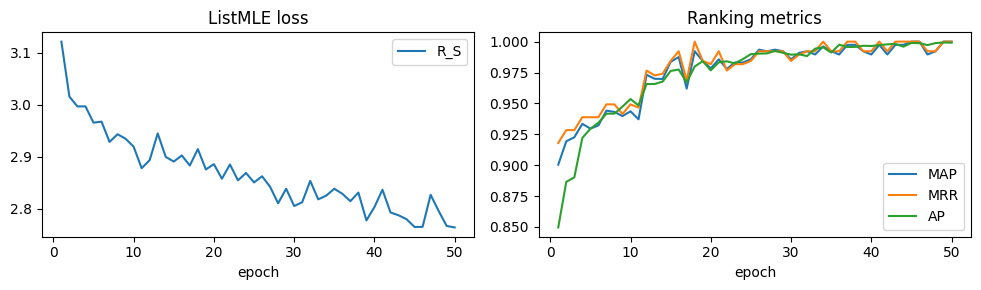

In [19]:
model, history = train_model(split_idx["train"], split_idx["val"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
history.plot(x="epoch", y="R_S", ax=ax[0], title="ListMLE loss")
history.plot(x="epoch", y=["MAP", "MRR", "AP"], ax=ax[1], title="Ranking metrics")
plt.tight_layout(); plt.show()

## 5.5 Sponsorship Scores & Ranked Result
依業配分數 $\hat{y}$ 由高到低排序，就是論文圖中最上面那排 Ranked Result。

In [20]:
eval_split = "train" if DATA_MODE == "pilot" else "test"
idx = split_idx[eval_split]

ranked = (posts.iloc[idx]
          .assign(score=predict(model, idx))
          .sort_values("score", ascending=False)
          .reset_index(drop=True))
ranked.index += 1                                   # 名次從 1 開始

print(f"[{eval_split}]", ranking_metrics(ranked["score"].values,
                                         ranked["label"].values, ranked["username"].values))
for k in [10, 20, 50]:
    print(f"前 {k} 名中業配比例：{ranked['label'].head(k).mean():.2f}")

pd.set_option("display.max_colwidth", 60)
display(ranked[["username", "label", "score", "text_masked"]].head(20))

[train] {'MAP': 1.0, 'MRR': 1.0, 'AP': 0.9991498430226163}
前 10 名中業配比例：1.00
前 20 名中業配比例：1.00
前 50 名中業配比例：1.00


,username,label,score,text_masked
1,ciao_kitchen,1,2.458267,"「LeTAO 如果出台灣限定口味?」🍪 復刻我每次去日本都會買的紅茶巧克力餅乾! 外層是薄薄酥脆的茶香餅乾, 中..."
2,crown_du,1,2.436666,"🪄⚡️飛航模飾每次聯名都讓人愛不釋手 所以我的第一次團購,就獻給他們了!💖 這次新品也整理詳細的文字介紹! 歡迎..."
3,nanaciaociao,1,2.431923,我真的是沒有搶演唱會的命...通常都是朋友幫我搶到門票🎟️ 到底是有什麼撇步大家可以告訴我嗎 好幾次手刀點進去、...
4,dr.acne_scar_queen,1,2.298597,"👩‍⚕️保養品就像處方箋,要針對皮膚問題,擦對成分才是重點! 雖然我很不喜歡病人擦保濕,但你擦的任何一罐保養品如..."
5,japanuts,1,2.298470,"速報!日本 PLAZA 2025年春季展示會注目商品分享! 這5款實在太讚啦,我當晚就立馬拆開來用了😍 目前在 ..."
6,shasha77.daily,1,2.256413,"最完美的睡姿不存ㄗ⋯⋯ 喜歡側睡錯了嗎 😠!|志祺七七 #shorts 💤 一顆不論怎麼睡,都抒壓的枕頭! 🔍 ..."
7,japanuts,1,2.254880,"經典日本零食這幾種吃法你試過嗎? 雖然他們單吃就不錯,但偶爾還是想變點新花樣💗 影片中一次分享了4個我自己常吃的..."
8,2uncle987,1,2.248843,下方留言你最喜歡吃什麼口味或想試什麼口味 我們就抽2位各送 6包!(隨機口味) 今天到台茂來會會我們辦公室零食區...
9,cindyhhh32,1,2.242736,上週去高雄看AAA 讓我13小時都不脫妝的秘密就是它 蘭芝小方塊氣墊! 超微米粉體可以緊貼肌膚 超級滑順很好拍開...
10,da_chien_huang,1,2.241055,POV: 如果我是自己的皮膚科醫生 還好我不是醫生 不然我的診所應該會收到一堆一星負評 身為多年抗痘的畢業生 講...


# 6. 正式實驗（預留）
- [ ] `DATA_MODE = "full"`，用 val 調參數、用 test 報告最終結果
- [ ] Ablation：有 / 沒有 Temporal Regularization（`w_l = 0`）
- [ ] Ablation：有 / 沒有刪除業配詞（`APPLY_MASK = False`）
- [ ] Ablation：Text only vs. Text + Video vs. Text + Video + Graph

In [21]:
# 範例：有 / 沒有 Temporal Regularization 的比較（pilot 也能跑，但只能當練習用）
results = {}
for name, w in [("with TR", W_L), ("no TR", 0.0)]:
    m, _ = train_model(split_idx["train"], split_idx["val"], w_l=w, verbose=False)
    ev = split_idx["train"] if DATA_MODE == "pilot" else split_idx["test"]
    results[name] = ranking_metrics(predict(m, ev), y[ev].cpu().numpy(), groups[ev])
pd.DataFrame(results).T.round(3)

,MAP,MRR,AP
with TR,1.0,1.0,0.999
no TR,1.0,1.0,0.999
